# Level 2, Task 1: House Price Prediction

- **Intern:** Malaika Saleem
- **Track:** Data Analytics
- **Program:** Oasis Infobyte Internship (OIBSIP)
- **Dataset:** Ames Housing data (`train.csv`)

## Objective
Build and evaluate a Linear Regression model that predicts house prices from features such as area, rooms, age, quality and location.

In [ ]:
import pandas as pd

df = pd.read_csv("train.csv")
print(f"Full dataset shape: {df.shape}")

cols = ["GrLivArea", "LotArea", "BedroomAbvGr", "FullBath",
        "YearBuilt", "Neighborhood", "OverallQual", "SalePrice"]
df = df[cols]

print(f"Selected shape: {df.shape}")
df.info()

Full dataset shape: (1460, 81)
Selected shape: (1460, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   GrLivArea     1460 non-null   int64
 1   LotArea       1460 non-null   int64
 2   BedroomAbvGr  1460 non-null   int64
 3   FullBath      1460 non-null   int64
 4   YearBuilt     1460 non-null   int64
 5   Neighborhood  1460 non-null   str  
 6   OverallQual   1460 non-null   int64
 7   SalePrice     1460 non-null   int64
dtypes: int64(7), str(1)
memory usage: 100.6 KB


# House Price Prediction using Linear Regression
**Oasis Infobyte Internship | Data Analytics | Level 2, Task 1**

## Step 1: Load Dataset and Initial Inspection
The Ames Housing dataset has 79 features. We select 8 relevant columns (area, rooms, age, location, quality) and the target `SalePrice`, then check shape and data types.

In [7]:
print(df.isnull().sum())
df.describe()

GrLivArea       0
LotArea         0
BedroomAbvGr    0
FullBath        0
YearBuilt       0
Neighborhood    0
OverallQual     0
SalePrice       0
dtype: int64


,GrLivArea,LotArea,BedroomAbvGr,FullBath,YearBuilt,OverallQual,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,1515.463699,10516.828082,2.866438,1.565068,1971.267808,6.099315,180921.195890
std,525.480383,9981.264932,0.815778,0.550916,30.202904,1.382997,79442.502883
min,334.000000,1300.000000,0.000000,0.000000,1872.000000,1.000000,34900.000000
25%,1129.500000,7553.500000,2.000000,1.000000,1954.000000,5.000000,129975.000000
50%,1464.000000,9478.500000,3.000000,2.000000,1973.000000,6.000000,163000.000000
75%,1776.750000,11601.500000,3.000000,2.000000,2000.000000,7.000000,214000.000000
max,5642.000000,215245.000000,8.000000,3.000000,2010.000000,10.000000,755000.000000


## Step 2: Null Check and Descriptive Statistics
We confirm missing values per column and look at mean, spread, min and max of each numeric feature to understand the data range.

**Observations:**
- The dataset has 1460 rows; after selecting 8 columns, shape is (1460, 8).
- All 8 columns show 1460 non-null values, so there are no missing values in the selected columns.
- 7 columns are numeric (int64) and `Neighborhood` is categorical (text), so it will need encoding later.

## Step 3: Distribution of Target Variable (SalePrice)
We plot the distribution of house prices to check its shape and skewness before modelling.

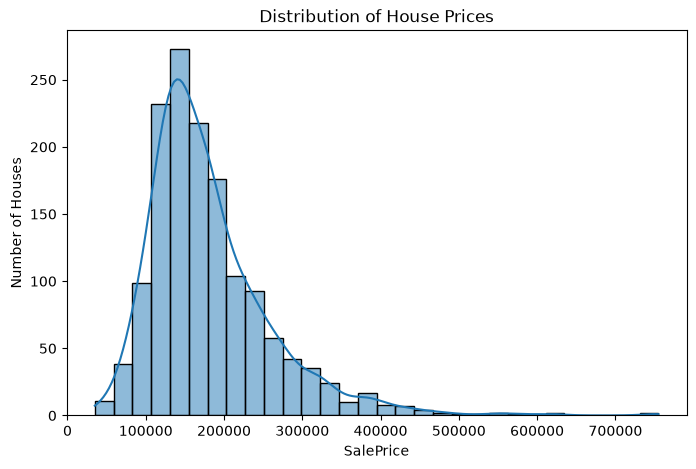

Skewness: 1.88


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["SalePrice"], bins=30, kde=True, ax=ax)
ax.set_title("Distribution of House Prices")
ax.set_xlabel("SalePrice")
ax.set_ylabel("Number of Houses")
plt.show()

print(f"Skewness: {df['SalePrice'].skew():.2f}")

**Observations:**
- Most houses are priced between about 100,000 and 250,000, with the peak near 150,000.
- The distribution is right-skewed (skewness = 1.88): a small number of expensive houses (up to about 750,000) form a long tail on the right.
- Because of these expensive houses, the mean price (about 180,921) is pulled above the typical house price.

## Step 4: Feature Selection Discussion
We chose 7 predictors based on real-world logic about what drives house prices:

- `GrLivArea` (living area): larger houses generally cost more.
- `LotArea` (plot size): bigger plots add value.
- `BedroomAbvGr` and `FullBath` (rooms): more bedrooms and bathrooms increase usability and price.
- `YearBuilt` (age): newer houses usually sell higher than older ones.
- `OverallQual` (quality rating 1-10): better materials and finish raise the price.
- `Neighborhood` (location): location strongly affects value. It is text, so it needs encoding before modelling.

Target variable: `SalePrice`.

## Step 5: Missing Values and Categorical Encoding
There are no missing values (checked in Step 2), so no imputation is needed. `Neighborhood` is text, so we apply One-Hot Encoding: each neighborhood becomes its own 0/1 column. `drop_first=True` removes one redundant column.

In [10]:
df_encoded = pd.get_dummies(df, columns=["Neighborhood"], drop_first=True, dtype=int)

print(f"Shape before: {df.shape}")
print(f"Shape after: {df_encoded.shape}")
df_encoded.head()

Shape before: (1460, 8)
Shape after: (1460, 31)


,GrLivArea,LotArea,BedroomAbvGr,FullBath,YearBuilt,OverallQual,SalePrice,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,...,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker
0,1710,8450,3,2,2003,7,208500,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1262,9600,3,2,1976,6,181500,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,1786,11250,3,2,2001,7,223500,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1717,9550,3,1,1915,7,140000,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2198,14260,4,2,2000,8,250000,0,0,0,...,1,0,0,0,0,0,0,0,0,0


**Observations:**
- The shape changed from (1460, 8) to (1460, 31): `Neighborhood` was replaced by 24 new 0/1 columns (25 neighborhoods minus 1 dropped).
- All values are now numeric, so the data is ready for Linear Regression.

## Step 6: Correlation Heatmap
We check how strongly each numeric feature is related to `SalePrice`. Values near +1 mean a strong positive relationship, and values near 0 mean little relationship.

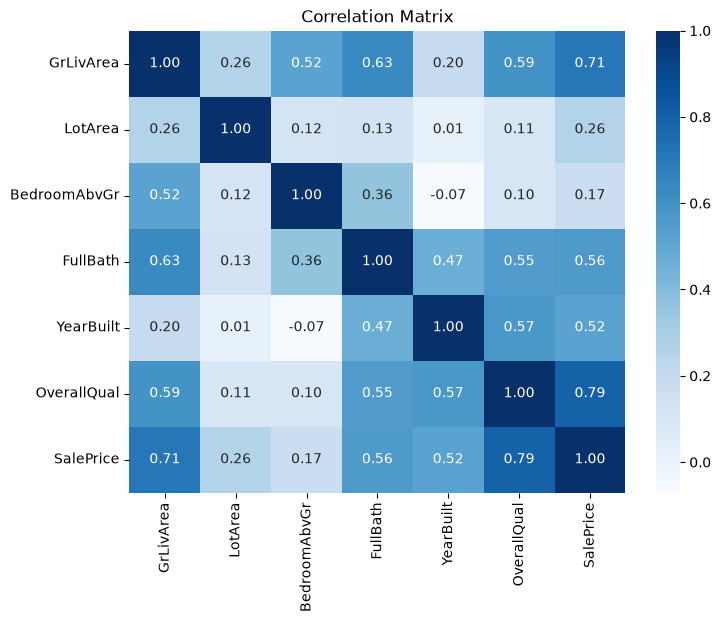

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
FullBath        0.560664
YearBuilt       0.522897
LotArea         0.263843
BedroomAbvGr    0.168213
Name: SalePrice, dtype: float64


In [12]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Correlation Matrix")
plt.show()

print(corr["SalePrice"].sort_values(ascending=False))

**Observations:**
- `OverallQual` (0.79) and `GrLivArea` (0.71) have the strongest positive correlation with `SalePrice`, so they are the most important predictors.
- `FullBath` (0.56) and `YearBuilt` (0.52) show a moderate positive relationship: more bathrooms and newer houses tend to cost more.
- `LotArea` (0.26) and `BedroomAbvGr` (0.17) have weak correlation with price.
- Some features are related to each other (e.g. `GrLivArea` and `FullBath` = 0.63), which is normal because larger houses usually have more bathrooms.

## Step 7: Train/Test Split
We separate the features (`X`) from the target (`y` = `SalePrice`), then split the data 80% for training and 20% for testing. The model learns from the training set and is evaluated on unseen test data.

In [14]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns="SalePrice")
y = df_encoded["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

X_train: (1168, 30)
X_test: (292, 30)


**Observations:**
- The 1460 houses were split into 1168 for training (80%) and 292 for testing (20%).
- Each house has 30 features (6 numeric + 24 neighborhood columns), and `SalePrice` is kept separately as the target.

## Step 8: Train Linear Regression Model
We create a Linear Regression model, train it on the training set (`fit`), and then predict house prices for the unseen test set (`predict`).

In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully.")
print(f"First 5 predicted prices: {y_pred[:5].round(0)}")
print(f"First 5 actual prices: {y_test.iloc[:5].values}")

Model trained successfully.
First 5 predicted prices: [145261. 336995. 103176. 171092. 268658.]
First 5 actual prices: [154500 325000 115000 159000 315500]


**Observations:**
- The model was trained successfully on 1168 houses and predicted prices for 292 unseen houses.
- For the first 5 test houses, predictions are reasonably close to actual prices (e.g. predicted 145,261 vs actual 154,500), but not exact. Evaluation metrics in the next step will measure the error precisely.

## Step 9: Model Evaluation
We evaluate the model on the test set using three metrics: Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R² score. RMSE is in the same unit as price, and R² shows how much of the price variation the model explains.

In [17]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE: {mse:,.0f}")
print(f"RMSE: {rmse:,.0f}")
print(f"R² score: {r2:.3f}")

MSE: 1,388,035,006
RMSE: 37,256
R² score: 0.819


**Observations:**
- R² score is 0.819, so the model explains about 82% of the variation in house prices on unseen data.
- RMSE is about 37,256, meaning predictions are off by roughly 37,000 on average. Compared to the mean price (about 180,921), this is an error of around 20%.
- MSE is large (about 1.39 billion) only because errors are squared. RMSE is easier to interpret.
- Overall, a simple Linear Regression with 7 features gives a good baseline.

## Step 10: Actual vs Predicted Prices
Each point is one test house. The red dashed line shows perfect predictions, so the closer the points are to this line, the better the model.

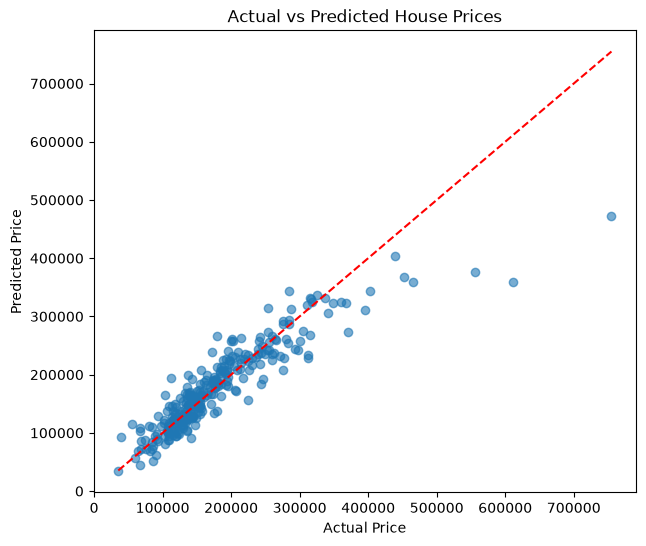

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, alpha=0.6)

line_min, line_max = y_test.min(), y_test.max()
ax.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--")

ax.set_title("Actual vs Predicted House Prices")
ax.set_xlabel("Actual Price")
ax.set_ylabel("Predicted Price")
plt.show()

**Observations:**
- Most points lie close to the red line, especially for houses priced between 100,000 and 300,000, so the model predicts typical houses well.
- For very expensive houses (above 400,000), the model under-predicts: for example, a house sold near 750,000 was predicted at about 470,000.
- This matches the right-skewed price distribution seen in Step 3: there are few expensive houses, so the model learns less about them.

## Step 11: Residual Plot
A residual is the actual price minus the predicted price (the model's error). If the model is suitable, residuals should be randomly scattered around zero with no clear pattern.

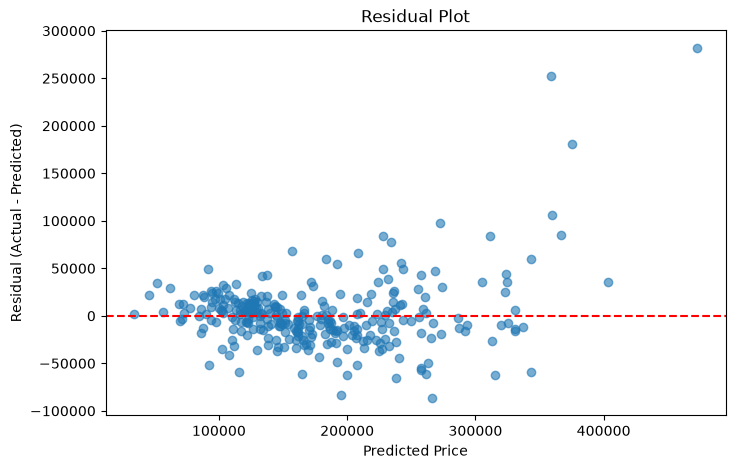

In [19]:
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred, residuals, alpha=0.6)
ax.axhline(0, color="red", linestyle="--")

ax.set_title("Residual Plot")
ax.set_xlabel("Predicted Price")
ax.set_ylabel("Residual (Actual - Predicted)")
plt.show()

**Observations:**
- For most houses (predicted price 50,000 to 300,000), residuals are scattered around zero, so the model has no strong bias in this range.
- The spread of residuals grows as predicted price increases (funnel shape): errors are larger for expensive houses.
- A few houses have very large positive residuals (up to about 280,000), meaning the model under-predicted them. This matches the pattern seen in the actual vs predicted plot.

## Step 12: Coefficient Analysis
Each coefficient shows how much `SalePrice` changes when that feature increases by one unit, keeping other features constant. Positive coefficients increase the price and negative ones decrease it.

In [20]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values("Coefficient", ascending=False)

print("Top 5 positive impact:")
print(coef_df.head(5).round(0))
print("\nTop 5 negative impact:")
print(coef_df.tail(5).round(0))

Top 5 positive impact:
                 Feature  Coefficient
21  Neighborhood_NridgHt      71723.0
27  Neighborhood_StoneBr      71218.0
20  Neighborhood_NoRidge      66200.0
29  Neighborhood_Veenker      56915.0
11  Neighborhood_Crawfor      43722.0

Top 5 negative impact:
                 Feature  Coefficient
3               FullBath      -1181.0
15  Neighborhood_MeadowV      -2486.0
2           BedroomAbvGr      -6023.0
6   Neighborhood_Blueste     -20602.0
7    Neighborhood_BrDale     -26211.0


**Observations:**
- The highest positive coefficients belong to neighborhoods such as NridgHt (+71,723), StoneBr (+71,218) and NoRidge (+66,200). Compared to the baseline neighborhood (Blmngtn), houses in these areas sell for much more, so location has a strong impact on price.
- BrDale (-26,211) and Blueste (-20,602) have the most negative impact, meaning houses there sell for less than in the baseline neighborhood.
- `BedroomAbvGr` (-6,023) and `FullBath` (-1,181) have small negative coefficients even though they correlate positively with price. This happens because the model already accounts for living area and quality, so extra rooms at the same size add little value.

## Step 13 (Bonus): Compare with Ridge and Lasso
Ridge and Lasso are regularised versions of Linear Regression that penalise large coefficients to reduce overfitting. We compare all three models on the same test set.

In [21]:
from sklearn.linear_model import Ridge, Lasso

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=50000),
}

results = []
for name, mdl in models.items():
    mdl.fit(X_train, y_train)
    pred = mdl.predict(X_test)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

pd.DataFrame(results).round(3)

,Model,RMSE,R2
0,Linear Regression,37256.342,0.819
1,Ridge,37214.105,0.819
2,Lasso,37245.674,0.819


**Observations:**
- All three models have the same R² (0.819) and almost the same RMSE (about 37,200).
- Ridge is marginally best (RMSE 37,214 vs 37,256 for Linear Regression), but the difference is tiny and not meaningful in practice.
- Regularisation gave no real improvement because we use only 7 features, so the plain Linear Regression model was not overfitting much.

## Conclusion

**Summary:** We built a Linear Regression model on the Ames Housing dataset using 7 features (living area, lot area, bedrooms, bathrooms, year built, overall quality and neighborhood). The model achieved an R² of 0.819 and an RMSE of about 37,256 on unseen test data.

**Key findings:**
- `OverallQual` and `GrLivArea` have the strongest correlation with price.
- Neighborhood has a large impact on price (e.g. NridgHt and StoneBr add over 70,000 compared to the baseline).
- Ridge and Lasso gave almost the same results as Linear Regression.

**Limitations:**
- The model under-predicts very expensive houses, and errors grow with price (seen in the residual plot).
- Prices are right-skewed (skewness 1.88).

**Possible improvements:** apply a log transform to `SalePrice`, add more features (e.g. basement area, garage), or try tree-based models such as Random Forest.